Всего записей в файле: 287679
После фильтрации (удалены пропуски): 287679 записей

[3/6] РАСЧЕТ МЕТРИК КАЧЕСТВА (горизонт 5 минут)...
Обучающая выборка: 203659 записей
Тестовая выборка: 50915 записей

Результаты:
  MAE        = 0.0085 ед.
  RMSE       = 0.0108 ед.
  MAPE (%)   = 558.0764 ед.
  R²         = 0.2771

[5/6] АНАЛИЗ ЗАВИСИМОСТИ ОШИБКИ ОТ ГОРИЗОНТА...
Диапазон горизонта: 1 – 29 дней

Горизонт  1 дн. | МАЕ = 0.0057 ед.
Горизонт  2 дн. | МАЕ = 0.0060 ед.
Горизонт  3 дн. | МАЕ = 0.0057 ед.
Горизонт  4 дн. | МАЕ = 0.0061 ед.
Горизонт  5 дн. | МАЕ = 0.0062 ед.
Горизонт  6 дн. | МАЕ = 0.0052 ед.
Горизонт  7 дн. | МАЕ = 0.0044 ед.
Горизонт  8 дн. | МАЕ = 0.0056 ед.
Горизонт 9 дн. | недостаточно данных, пропуск
Горизонт 10 дн. | недостаточно данных, пропуск
Горизонт 11 дн. | недостаточно данных, пропуск
Горизонт 12 дн. | недостаточно данных, пропуск
Горизонт 13 дн. | недостаточно данных, пропуск
Горизонт 14 дн. | недостаточно данных, пропуск
Горизонт 15 дн. | недостаточно данных, про

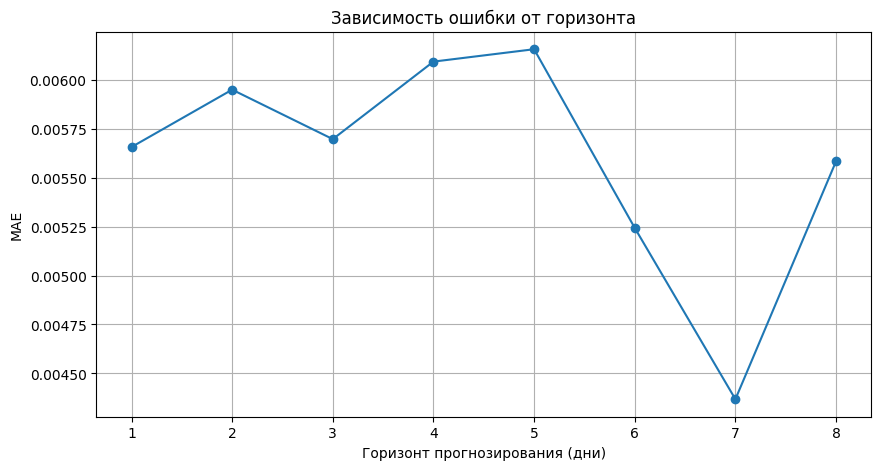


График сохранён как 'error_vs_horizon_days.png'

[6/6] НАГРУЗОЧНОЕ ТЕСТИРОВАНИЕ (ПАКЕТНАЯ ОБРАБОТКА)...
Размер пакета | Общее время | На 1 запрос | Пропускная способность
----------------------------------------------------------------------
     1     |   0.0020 сек |    2.00 мс |      499 зап/сек
    10     |   0.0030 сек |    0.30 мс |     3366 зап/сек
    50     |   0.0030 сек |    0.06 мс |    16684 зап/сек
   100     |   0.0030 сек |    0.03 мс |    33479 зап/сек
   500     |   0.0040 сек |    0.01 мс |   123989 зап/сек
  1000     |   0.0040 сек |    0.00 мс |   250646 зап/сек

✅ Все тесты завершены.


In [5]:
import pandas as pd
import numpy as np
import json
import time
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor, Pool
import matplotlib.pyplot as plt

# ------------------------------
# 1. Загрузка и фильтрация
# ------------------------------
def load_and_filter(file_path):
    df = pd.read_csv(file_path)
    print(f"Всего записей в файле: {len(df)}")
    
    # Извлечение числовых значений из JSON-столбцов
    def extract_usage(json_str, key):
        try:
            return json.loads(json_str.replace("'", '"'))[key]
        except:
            return np.nan
    
    df['cpu_avg'] = df['average_usage'].apply(lambda x: extract_usage(x, 'cpus'))
    df['mem_avg'] = df['average_usage'].apply(lambda x: extract_usage(x, 'memory'))
    df['cpu_max'] = df['maximum_usage'].apply(lambda x: extract_usage(x, 'cpus'))
    df['mem_max'] = df['maximum_usage'].apply(lambda x: extract_usage(x, 'memory'))
    
    # Преобразование времени
    df['start_dt'] = pd.to_datetime(df['start_time'], unit='us')
    
    # Удаление строк с пропущенными целевыми значениями
    df = df.dropna(subset=['cpu_avg', 'mem_avg'])
    
    # Удаление неинформативных колонок
    cols_to_drop = ['average_usage', 'maximum_usage', 'random_sample_usage',
                    'cpu_usage_distribution', 'tail_cpu_usage_distribution',
                    'cycles_per_instruction', 'memory_accesses_per_instruction',
                    'sample_rate', 'page_cache_memory', 'end_time']
    df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])
    
    print(f"После фильтрации (удалены пропуски): {len(df)} записей")
    return df

# ------------------------------
# 2. Подготовка признаков для прогноза на один шаг (5 минут)
# ------------------------------
def prepare_features_step(df, horizon=1):
    """Возвращает X, y, cat_features для прогноза через horizon шагов (5 минут)"""
    df = df.sort_values(['collection_id', 'machine_id', 'start_dt'])
    df['target'] = df.groupby(['collection_id', 'machine_id'])['cpu_avg'].shift(-horizon)
    df = df.dropna(subset=['target'])
    
    # Числовые признаки
    numeric_cols = ['assigned_memory', 'cpu_avg', 'mem_avg', 'cpu_max', 'mem_max']
    for lag in [1, 2, 3]:
        df[f'cpu_lag{lag}'] = df.groupby(['collection_id', 'machine_id'])['cpu_avg'].shift(lag)
        df[f'mem_lag{lag}'] = df.groupby(['collection_id', 'machine_id'])['mem_avg'].shift(lag)
        numeric_cols += [f'cpu_lag{lag}', f'mem_lag{lag}']
    
    # Категориальные признаки
    cat_cols = ['collection_id', 'machine_id']
    # Временные признаки
    df['hour'] = df['start_dt'].dt.hour
    df['dayofweek'] = df['start_dt'].dt.dayofweek
    numeric_cols += ['hour', 'dayofweek']
    
    all_features = cat_cols + numeric_cols
    df = df.dropna(subset=all_features + ['target'])
    
    X = df[all_features]
    y = df['target']
    return X, y, cat_cols

# ------------------------------
# 3. Расчёт метрик качества (горизонт 1 шаг)
# ------------------------------
def train_and_evaluate(X, y, cat_features):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    print(f"Обучающая выборка: {len(X_train)} записей")
    print(f"Тестовая выборка: {len(X_test)} записей")
    
    model = CatBoostRegressor(iterations=300, learning_rate=0.03, depth=6,
                              loss_function='RMSE', verbose=False, random_seed=42)
    model.fit(X_train, y_train, cat_features=cat_features, verbose=False)
    y_pred = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mape = np.mean(np.abs((y_test - y_pred) / (y_test + 1e-8))) * 100
    r2 = r2_score(y_test, y_pred)
    
    metrics = {'MAE': mae, 'RMSE': rmse, 'MAPE (%)': mape, 'R²': r2}
    return model, metrics, (X_test, y_test, y_pred)

# ------------------------------
# 4. Анализ зависимости ошибки от горизонта (агрегация по дням, горизонт 1..29 дней)
# ------------------------------
def prepare_daily_data(df):
    """Агрегирует данные по дням (среднее CPU за день) для прогноза на дни вперёд"""
    df['date'] = df['start_dt'].dt.date
    daily = df.groupby(['collection_id', 'machine_id', 'date']).agg(
        cpu_daily=('cpu_avg', 'mean')
    ).reset_index()
    daily = daily.sort_values(['collection_id', 'machine_id', 'date'])
    return daily

def analyze_horizon_days(df, max_days=29):
    daily = prepare_daily_data(df)
    print(f"\n[5/6] АНАЛИЗ ЗАВИСИМОСТИ ОШИБКИ ОТ ГОРИЗОНТА...")
    print(f"Диапазон горизонта: 1 – {max_days} дней\n")
    
    mae_list = []
    horizons = range(1, max_days+1)
    
    for h in horizons:
        # Создаём лаговые признаки на уровне дней
        X_list, y_list = [], []
        for (cid, mid), group in daily.groupby(['collection_id', 'machine_id']):
            if len(group) <= h:
                continue
            group = group.sort_values('date')
            for i in range(len(group) - h):
                # Признаки: лаги 1,2,3 дня
                lag1 = group.iloc[i]['cpu_daily'] if i >= 0 else np.nan
                lag2 = group.iloc[i-1]['cpu_daily'] if i >= 1 else np.nan
                lag3 = group.iloc[i-2]['cpu_daily'] if i >= 2 else np.nan
                if np.isnan(lag1) or np.isnan(lag2) or np.isnan(lag3):
                    continue
                X_list.append([lag1, lag2, lag3])
                y_list.append(group.iloc[i+h]['cpu_daily'])
        
        if len(X_list) < 100:
            print(f"Горизонт {h} дн. | недостаточно данных, пропуск")
            continue
        
        X = np.array(X_list)
        y = np.array(y_list)
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
        model = CatBoostRegressor(iterations=200, learning_rate=0.05, depth=5,
                                  loss_function='RMSE', verbose=False, random_seed=42)
        model.fit(X_train, y_train, verbose=False)
        y_pred = model.predict(X_test)
        mae = mean_absolute_error(y_test, y_pred)
        mae_list.append(mae)
        print(f"Горизонт {h:2d} дн. | МАЕ = {mae:.4f} ед.")
    
    return horizons[:len(mae_list)], mae_list

# ------------------------------
# 5. Нагрузочное тестирование (пакетная обработка)
# ------------------------------
def load_testing(model, X_sample, batch_sizes=[1, 10, 50, 100, 500, 1000]):
    print("\n[6/6] НАГРУЗОЧНОЕ ТЕСТИРОВАНИЕ (ПАКЕТНАЯ ОБРАБОТКА)...")
    print("Размер пакета | Общее время | На 1 запрос | Пропускная способность")
    print("-" * 70)
    
    for batch in batch_sizes:
        # Создаём пакет из batch копий одной и той же строки
        batch_data = pd.concat([X_sample] * batch, ignore_index=True)
        start = time.time()
        _ = model.predict(batch_data)
        elapsed = time.time() - start
        per_req = elapsed / batch * 1000  # мс
        throughput = batch / elapsed      # зап/сек
        print(f"{batch:6d}     | {elapsed:8.4f} сек | {per_req:7.2f} мс | {throughput:8.0f} зап/сек")

# ------------------------------
# 6. Основной блок
# ------------------------------
if __name__ == "__main__":
    # Шаг 1: фильтрация
    df = load_and_filter("Data/Dataset-24.csv")
    
    # Шаг 2: подготовка для горизонта = 1 (5 минут)
    X, y, cat_features = prepare_features_step(df, horizon=1)
    
    # Шаг 3: обучение и метрики качества
    print("\n[3/6] РАСЧЕТ МЕТРИК КАЧЕСТВА (горизонт 5 минут)...")
    model, metrics, test_data = train_and_evaluate(X, y, cat_features)
    print("\nРезультаты:")
    for k, v in metrics.items():
        print(f"  {k:10s} = {v:.4f}" + (" ед." if k != 'R²' else ""))
    
    # Шаг 4: анализ горизонта в днях
    horizons_days, mae_days = analyze_horizon_days(df, max_days=29)
    
    # Построение графика (опционально)
    if len(horizons_days) > 0:
        plt.figure(figsize=(10, 5))
        plt.plot(horizons_days, mae_days, marker='o', linestyle='-')
        plt.xlabel("Горизонт прогнозирования (дни)")
        plt.ylabel("MAE")
        plt.title("Зависимость ошибки от горизонта")
        plt.grid(True)
        plt.savefig("error_vs_horizon_days.png", dpi=100)
        plt.show()
        print("\nГрафик сохранён как 'error_vs_horizon_days.png'")
    
    # Шаг 5: нагрузочное тестирование
    # Берём один объект из тестовой выборки для пакетов
    X_test, _, _ = test_data
    sample = X_test.iloc[[0]]
    load_testing(model, sample)
    
    print("\n✅ Все тесты завершены.")